# Essendon Voting Centre Swings

In [2]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import folium

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root / "scripts"))

In [3]:
from vecResults import getVotingCentres, normaliseName
from votingLocations import getVotingLocations


results2018 = getVotingCentres(2018)
results2022 = getVotingCentres(2022)

In [4]:
parties = ["Labor", "Liberal", "Greens"]


def prepBooths(results, year):
    booths = results[results["voteType"] == "ordinary"].copy()
    booths["nameKey"] = booths["votingCentre"].map(normaliseName)
    booths["formalVotes"] = booths["totalVotes"] - booths["informal"]

    for party in parties:
        booths[f"{party}{year}"] = 100 * booths[party] / booths["formalVotes"]

    return booths[
        ["votingCentre", "nameKey", "formalVotes"] +
        [f"{party}{year}" for party in parties]
    ]


booths2018 = prepBooths(results2018, 2018)
booths2022 = prepBooths(results2022, 2022)

matched = booths2018.merge(
    booths2022,
    on="nameKey",
    how="outer",
    indicator=True,
    suffixes=("2018", "2022"),
    validate="one_to_one"
)

display(matched.loc[matched["_merge"] != "both", ["nameKey", "_merge"]])

,nameKey,_merge
2,ascot vale west,left_only


In [5]:
swings = matched.loc[matched["_merge"] == "both"].copy()
swings["votingCentre"] = swings["votingCentre2022"]

for party in parties:
    swings[f"{party}Swing"] = swings[f"{party}2022"] - swings[f"{party}2018"]

swings[["votingCentre", "LaborSwing", "LiberalSwing", "GreensSwing"]].round(2)

,votingCentre,LaborSwing,LiberalSwing,GreensSwing
0,Ascot Vale Central,-4.59,1.03,-2.30
1,Ascot Vale East,-7.62,2.66,-5.57
3,Buckley Park,0.38,-4.92,1.83
4,Essendon,-3.36,1.45,1.89
5,Essendon North,-5.14,1.55,2.01
6,Essendon West,-2.89,4.90,-1.19
7,Flemington,-14.30,0.14,0.35
8,Glenbervie,-8.00,3.24,-1.55
9,Moonee Ponds,-1.29,1.53,4.25
10,Moonee Ponds Central,-7.52,1.92,1.34


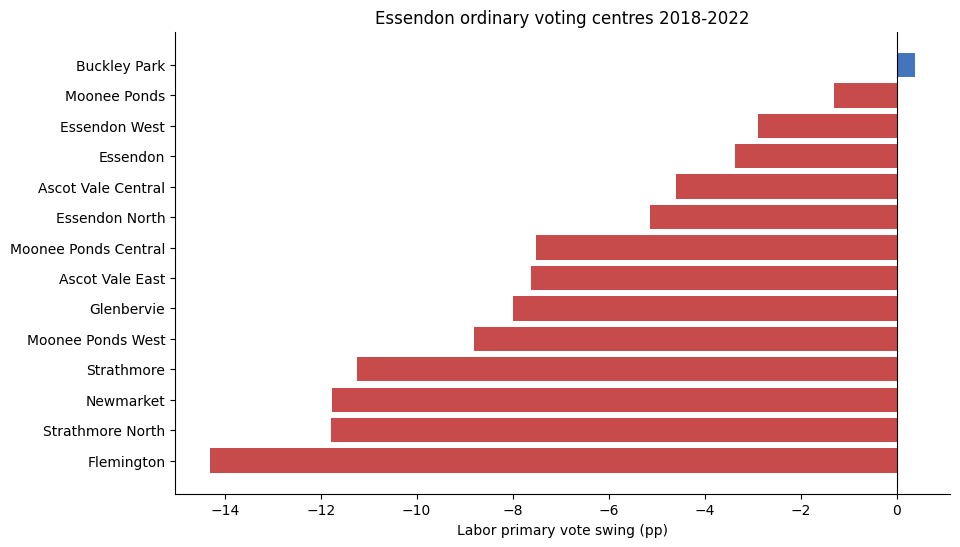

In [6]:
plotData = swings.sort_values("LaborSwing")
colors = ["#c84b4b" if x < 0 else "#4275bd" for x in plotData["LaborSwing"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plotData["votingCentre"], plotData["LaborSwing"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Labor primary vote swing (pp)")
ax.set_title("Essendon ordinary voting centres 2018-2022")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<Axes: xlabel='LaborSwing', ylabel='LiberalSwing'>

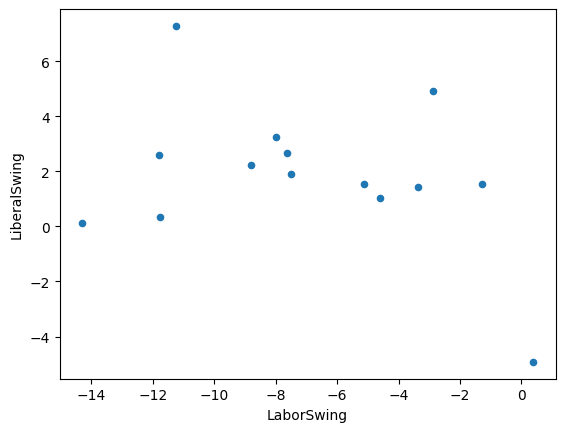

In [7]:
swings[["LaborSwing", "LiberalSwing"]].plot(
    kind="scatter", x="LaborSwing", y="LiberalSwing")

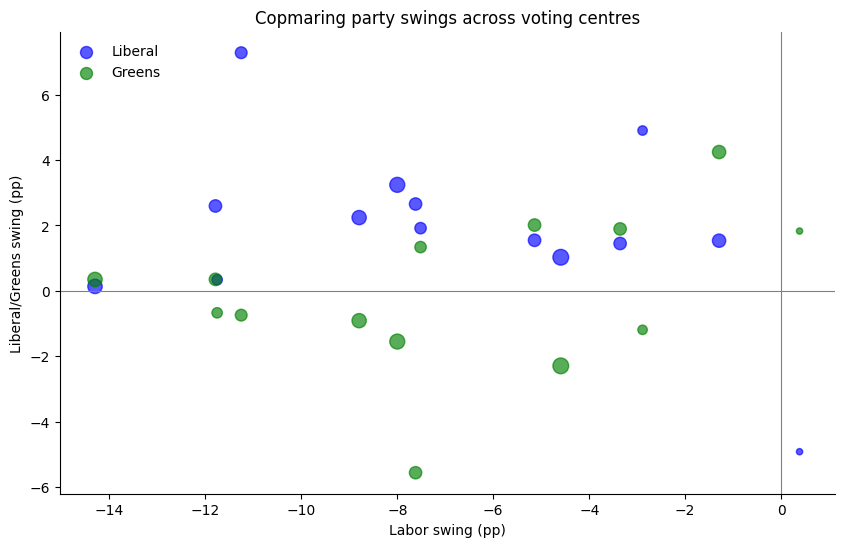

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(swings["LaborSwing"], swings["LiberalSwing"],
           s=swings["formalVotes2022"] / 12, alpha=0.65, label="Liberal", color="blue")
ax.scatter(swings["LaborSwing"], swings["GreensSwing"],
           s=swings["formalVotes2022"] / 12, alpha=0.65, label="Greens", color="green")

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Labor swing (pp)")
ax.set_ylabel("Liberal/Greens swing (pp)")
ax.set_title("Copmaring party swings across voting centres")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Mapping the voting centres

In [9]:
locations = getVotingLocations()

locations["nameKey"] = locations["votingCentre"].map(normaliseName)

locations = locations[locations["nameKey"].isin(swings["nameKey"])].copy()

if locations["nameKey"].duplicated().any():
    raise ValueError("Duplicate locations")

mapped = swings.merge(
    locations[["nameKey", "latitude", "longitude"]],
    on="nameKey",
    how="left",
    validate="one_to_one"
)

centre = [mapped["latitude"].mean(), mapped["longitude"].mean()]
electionMap = folium.Map(location=centre, zoom_start=13)

for _, booth in mapped.iterrows():
    swing = booth["LaborSwing"]
    color = "#c84b4b" if swing > 0 else "#4275bd"

    desc = (
        f"<b>{booth["votingCentre"]}</b>"
        f"<p>Labor swing: {swing:+.2f} p</p>"
        f"<p>Liberal swing: {booth["LiberalSwing"]:+.2f} pp</p>"
        f"<p>Greens swing: {booth["GreensSwing"]:+.2f} pp</p>"
    )

    folium.CircleMarker(
        location=[booth["latitude"], booth["longitude"]],
        radius=5 * abs(swing) / 2,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        popup=folium.Popup(desc, max_width=250),
        tooltip=booth["votingCentre"]
    ).add_to(electionMap)

electionMap